In [246]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar


In [247]:
# Import the data
booking_data = pd.read_csv("../data/Hotel_bookings.csv")

In [248]:
print (booking_data.head(5))

   IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
0           0         6             2015             July   
1           1        88             2015             July   
2           1        65             2015             July   
3           1        92             2015             July   
4           1       100             2015             July   

   ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
0                     27                      1                     0   
1                     27                      1                     0   
2                     27                      1                     0   
3                     27                      1                     2   
4                     27                      2                     0   

   StaysInWeekNights  Adults  Children  ...      DepositType        Agent  \
0                  2       1       0.0  ...  No Deposit                 6   
1                  4       2       0.0  

In [249]:
print (booking_data.describe())

         IsCanceled      LeadTime  ArrivalDateYear  ArrivalDateWeekNumber  \
count  79330.000000  79330.000000     79330.000000           79330.000000   
mean       0.417270    109.735724      2016.174285              27.177449   
std        0.493111    110.948526         0.699181              13.398523   
min        0.000000      0.000000      2015.000000               1.000000   
25%        0.000000     23.000000      2016.000000              17.000000   
50%        0.000000     74.000000      2016.000000              27.000000   
75%        1.000000    163.000000      2017.000000              38.000000   
max        1.000000    629.000000      2017.000000              53.000000   

       ArrivalDateDayOfMonth  StaysInWeekendNights  StaysInWeekNights  \
count           79330.000000          79330.000000       79330.000000   
mean               15.786625              0.795185           2.182957   
std                 8.728451              0.885026           1.456416   
min           

In [250]:
print (booking_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  str    
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  str    
 12  Country                      79306 non-null  str    
 13  MarketSegment              

> 💡 **Data Exploration and Analysis**

In [251]:
# See the unique values of each column
# The aim for this is to see if missing values (not null) in any column like having 0s when it shouldn't
for column in booking_data.columns:
    print(f"Unique values in {column}: {booking_data[column].unique()}")

Unique values in IsCanceled: [0 1]
Unique values in LeadTime: [  6  88  65  92 100  79   3  63  62  43   4  97  80  60 106  68  18  71
  85  75  89  83  72 111  86  73  55  69  76  61  77  54  90 117 105  51
  24  84 115  67  87 109  96 114  66  59 122 123  94 120   0 125  82 107
 103  12 118 108 119  20  22  99 112  93 132 110   2  15  98 124  16  19
  81   5  27  25 126  74   1  64 138 102  78 130 135   7  28  34 141  33
 101  13  11  36 128  30 145 142  39 121 147 140 104  41 134 150   8 133
  10  40 131   9 137 127  46  47  14 151  17  44 113  53  50 162 148 149
  21  23  37  49  26  32  52 173  45 164  42  58  48 168  31  38 175 170
  29  35 167 166  56 152 155 116  95  57 179  70 192 169 193 199 204 200
  91 198 158 210 156 174 184 180 195 216 233 212 139 242 208 146 144 159
 197 129 160 154 393 251 157 161 136 182 267 274 268 190 281 188 275 270
 265 288 143 295 443 194 437 253 207 302 259 178 289 298 286 309 196 273
 276 297 191 451 217 323 316 189 322 211 163 172 153 205 202 3

> 💡 **Data insights**

In [252]:
# IsCanceled => No issues or anomalies.
# LeadTime => It has 0s. However, this is totally valid as 0 means that customer has arrived in the same date of entering the PMS. 
# ArrivalDateYear => No issues or anomalies.
# ArrivalDateMonth => No issues or anomalies.
# ArrivalDateWeekNumber => has values of (53). Is this valid? [Note: A year has only 52 years].
# ArrivalDateDayOfMonth => No issues or anomalies as all values range between 1-31. However, we still need to check for inconsistencies like 31st Feb, 30th Feb, 31st April, and so on.
# StaysInWeekendNights => No issues or anomalies. "0" here has a meaning. 
# StaysInWeekNights => No issues or anomalies. "0" here has a meaning.
# Adults => It has 0s. How a reservation can be made with 0 adults?
# Children => It has 4 missing values. These rows need to be removed.
# Babies => Bookings with 9 and 10 babies? Wow. May be outliers! 
# Meal => No issues or anomalies
# Country => It has 24 missing values and rare classes with 1 existance. May need to be removed. 
# MarketSegment => There is no Nulls, however, the 8th class (Undefined) has found in only 2 rows which most probably will be removed to avoid noise. 
# DistributionChannel => There is no Nulls, however, the 5th class (Undefined) has found in only 4 rows which most probably will be removed to avoid noise. 
# IsRepeatedGuest => No issues or anomalies.
# PreviousCancellations => No missing values, however, the values 11, 13, and 21 may be outliers. Note: "0" has a meaning.
# PreviousBookingsNotCanceled => No missing values, may have outlies (will be discoved from BoxPlot). Note: "0" has a meaning.
# ReservedRoomType => No missing values or anomalies.
# AssignedRoomType => No missing values. Having a new room type "K" which didn't exist in "ReservedRoomType" is totally normal. It may be an operational or upgrade room that offered by the hotel itself and not available for publics for reservation.
# BookingChanges => No incorrect values or missing ones. However, values like "20" may be outliers and cause skewness of data. So, outliers may be removed.
# DepositType => No wrong categories or missing values.
# Agent => It has 8131 "NULL" values. However, this is fine as "NULL" here means that the customer made the reservation itself without any travel agent. We still need to investigate on how "NULL" should be presented. It may have to be replaced with other category like "Direct" for example. Note: For linear models, we may use "Target Encoding" to replace the "NULL" values with the mean of the target variable (IsCanceled) for that category.
# Company => It has 75641 "NULL" values. This is fine and means that customer didn't book through a company.
# DaysInWaitingList => 0 has a meaning here. So, all data values are valid. However, we need to check for outliers.
# CustomerType => No missing values or anomalies.
# ADR => It has 1208 "0" values. 1079 of them weren't cancelled. Were they free stays? [We need to handle this].
# RequiredCarParkingSpaces => No issues in the data.
# TotalOfSpecialRequests => No issues in the data. 
# ReservationStatus => No isses. All data values fall within the original cited categories.
# ReservationStatusDate => No issues in the data.

In [253]:
print(booking_data[(booking_data['StaysInWeekNights'] == 0) & (booking_data['StaysInWeekendNights'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    308
1     23
Name: count, dtype: int64


In [254]:
zero_nights_condition = (booking_data['StaysInWeekNights'] == 0) & (booking_data['StaysInWeekendNights'] == 0)
print(booking_data[zero_nights_condition & (booking_data['IsCanceled'] == 1)]['ReservationStatus'].value_counts())

ReservationStatus
Canceled    16
No-Show      7
Name: count, dtype: int64


In [255]:
# As expected, in all 23 bookings with 0 nights, the reservation status is "Canceled". This is a valid case as the customer may have made a reservation and then canceled it before arriving at the hotel:
# 16 => Cancelled by the customer.
# 7 => Cancelled by the hotel as  customer didn't arrive at the hotel (No-Show). 
# The other uncancelled 308 bookings will be removed.

In [256]:
# Let's get the number of bookings with 0 ADR and see if they are cancelled or not.
print(booking_data[booking_data['ADR'] == 0]['IsCanceled'].value_counts())

IsCanceled
0    1079
1     129
Name: count, dtype: int64


In [257]:
# Let's get the number of bookings with 0 adults and see if they are cancelled or not.
print (booking_data[booking_data['Adults'] == 0]['IsCanceled'].value_counts())

IsCanceled
0    283
1    107
Name: count, dtype: int64


In [258]:
# Uh! There are 390 bookings with 0 adults:
# 107 of them are cancelled (Make sense).
# 283 of them are not cancelled which means that they are confirmed without any adults. This is a serious anomaly and may need to be removed from the dataset.

In [259]:
# Let's get the number of bookings with 0 adults, 0 children, and 0 babies and see if they are cancelled or not (Edge case)
print (booking_data[(booking_data['Adults'] == 0) & (booking_data['Children'] == 0) & (booking_data['Babies'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    144
1     23
Name: count, dtype: int64


In [260]:
# There are 144 bookings made already and not cancelled without any adults, children, or babies.
# Note: These rows will be removed most probably as they are not valid bookings.

In [261]:
# Let's see the number of bookings made with children only.
print (booking_data[(booking_data['Adults'] == 0) & (booking_data['Children'] > 0) & (booking_data['Babies'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    137
1     83
Name: count, dtype: int64


In [262]:
# We have 137 booking with children only. These rows will be most probably removed as they are invalid.

In [263]:
df = booking_data
df.dtypes.value_counts()

int64      16
str        13
float64     2
Name: count, dtype: int64

In [264]:
df.select_dtypes(include='float').columns.tolist()

['Children', 'ADR']

In [265]:
# Number of children should be int not float
df[df['Children'] % 1 != 0]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
540,1,2,2015,August,32,3,1,0,2,NaN,...,No Deposit,NULL,NULL,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
607,1,1,2015,August,32,5,0,2,2,NaN,...,No Deposit,14,NULL,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
619,1,1,2015,August,32,5,0,2,3,NaN,...,No Deposit,NULL,NULL,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
1100,1,8,2015,August,33,13,2,5,2,NaN,...,No Deposit,9,NULL,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [266]:
# The column got a float data type because of these NaNs
# There are no float values but the column need to be converted to int after dealing with the NaNs
df['Children'].value_counts()

Children
0.0    74220
1.0     3023
2.0     2024
3.0       59
Name: count, dtype: int64

In [267]:
df.isna().sum()[df.isna().sum() > 0]
# Children contains 4 NaN and Country contains 24

Children     4
Country     24
dtype: int64

## Duplicates

In [268]:
df.duplicated().sum()
# The dataset does not include a booking ID, so identical rows may be duplicates and may be similar valid bookings 
# Maybe an agency is booking several identical rooms for its employees at the same time
# This is a leakage risk. If identical rows land in both train and test splits, the model is partly tested on rows it has memorized
# So we must group the duplicates and put each group in the train or test split

np.int64(25902)

In [269]:
group_sizes = df.groupby(list(df.columns), dropna=False).size() # All the simillar rows will form one group
group_sizes = group_sizes[group_sizes > 1]      # dropna=False to include the rows contain na in the groups

print("Number of duplicate groups:", len(group_sizes))
print("\n\n", group_sizes.describe())
print("\n\nMost common group sizes:")
print(group_sizes.value_counts().head(10))

Number of duplicate groups: 5846


 count    5846.000000
mean        5.430722
std         9.334461
min         2.000000
25%         2.000000
50%         2.000000
75%         4.000000
max       180.000000
dtype: float64


Most common group sizes:
2     3502
3      679
4      353
5      204
6      114
10      98
20      86
8       79
7       75
9       69
Name: count, dtype: int64


In [270]:
is_dup_member = df.duplicated(keep=False)

print("Overall cancel rate:        ", round(df["IsCanceled"].mean(), 4))
print("After drop_duplicates():    ", round(df.drop_duplicates()["IsCanceled"].mean(), 4))
print()
print(df.groupby(is_dup_member, dropna=False)["IsCanceled"].agg(n_rows="size", cancel_rate="mean")   # makes 2 groups for dups and not dups 
        .rename(index={False: "not in a dup group", True: "in a dup group"}))

Overall cancel rate:         0.4173
After drop_duplicates():     0.3004

                    n_rows  cancel_rate
not in a dup group   47582     0.286558
in a dup group       31748     0.613172


In [271]:
for c in ["MarketSegment", "DistributionChannel", "DepositType", "CustomerType"]:
    print(pd.crosstab(df[c], is_dup_member, normalize="columns").round(3)   #normalize converts counts into percentages.
            .rename(columns={False: "unique", True: "dup member"}), "\n")

col_0          unique  dup member
MarketSegment                    
Aviation        0.005       0.001
Complementary   0.010       0.002
Corporate       0.042       0.031
Direct          0.109       0.029
Groups          0.031       0.394
Offline TA/TO   0.123       0.343
Online TA       0.681       0.200
Undefined       0.000       0.000 



col_0                unique  dup member
DistributionChannel                    
Corporate             0.049       0.033
Direct                0.119       0.035
GDS                   0.004       0.001
TA/TO                 0.828       0.931
Undefined             0.000       0.000 

col_0            unique  dup member
DepositType                        
No Deposit        0.996       0.601
Non Refund        0.004       0.399
Refundable        0.000       0.000 

col_0            unique  dup member
CustomerType                       
Contract          0.028       0.031
Group             0.005       0.001
Transient         0.866       0.573
Transient-Party   0.101       0.395 



## Validations


In [272]:
placeholder_tokens = ["", "NULL", "NA", "na", "N/A", "nan", "NaN", "None", "Undefined"]

n_nan = df.isna().sum()
n_placeholder = pd.Series({
    c: df[c].dropna().astype(str).str.strip().isin(placeholder_tokens).sum() for c in df.columns
})

missing_report = pd.DataFrame({"n_nan": n_nan, "n_placeholder": n_placeholder})

missing_report[(missing_report["n_nan"] > 0) | (missing_report["n_placeholder"] > 0)]
    

,n_nan,n_placeholder
Children,4,0
Country,24,0
MarketSegment,0,2
DistributionChannel,0,4
Agent,0,8131
Company,0,75641


In [273]:
df['Company'].value_counts()

Company
NULL    75641
  40      924
  67      267
  45      250
 153      215
        ...  
 481        1
 491        1
 494        1
 497        1
 421        1
Name: count, Length: 208, dtype: int64

In [274]:
# Are there Impossible dates?

month_map = {name: i for i, name in enumerate(calendar.month_name)}
month_num = df["ArrivalDateMonth"].map(month_map)

arrival_date = pd.to_datetime(
    dict(year=df["ArrivalDateYear"], month=month_num, day=df["ArrivalDateDayOfMonth"]),
    errors="coerce",
)
print("Impossible dates (31 Feb):", arrival_date.isna().sum())

# No Impossible dates in the data


Impossible dates (31 Feb): 0


In [275]:
week = df["ArrivalDateWeekNumber"]

week_53 = (week == 53)
print("Rows with week 53:", week_53.sum(), '\n')
arrival_date[week_53].groupby(arrival_date[week_53].dt.year).agg(["min", "max"])

Rows with week 53: 1198 



,min,max
2015,2015-12-27,2015-12-31
2016,2016-12-25,2016-12-31


In [276]:
print("ReservationStatus and IsCanceled: \n")
pd.crosstab(df["ReservationStatus"], df["IsCanceled"])

# The two columns match

ReservationStatus and IsCanceled: 



IsCanceled,0,1
ReservationStatus,,
Canceled,0,32186
Check-Out,46228,0
No-Show,0,916


In [277]:
prev_can = df["PreviousCancellations"]
prev_nc = df["PreviousBookingsNotCanceled"]
has_history = (prev_can + prev_nc) > 0
print("IsRepeatedGuest and having previous bookings: \n")
pd.crosstab(df["IsRepeatedGuest"], has_history, colnames=["has previous bookings"])

# There are repeated guests without previous bookings whether cancelled or not 


IsRepeatedGuest and having previous bookings: 



has previous bookings,False,True
IsRepeatedGuest,,
0,72492,4806
1,296,1736


In [278]:
mask = (df["IsRepeatedGuest"] == 0) & (df["PreviousBookingsNotCanceled"] > 0)
print("Not repeated but has previous not-canceled bookings:", mask.sum())

# Also a problem

Not repeated but has previous not-canceled bookings: 173


In [279]:

print("MarketSegment and DistributionChannel: \n")
pd.crosstab(df["MarketSegment"], df["DistributionChannel"])

# There are many overlaps

MarketSegment and DistributionChannel: 



DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


## > 💡 **Data Visualization**

In [280]:
num_cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children",
            "Babies", "PreviousCancellations", "PreviousBookingsNotCanceled",
            "BookingChanges", "DaysInWaitingList", "RequiredCarParkingSpaces",
            "TotalOfSpecialRequests", "ADR"]
num = df[num_cols].apply(pd.to_numeric, errors="coerce")

In [281]:
df.describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79326.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091370,0.004941,0.025615,0.079743,0.132371,0.187369,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372177,0.084323,0.157983,0.415472,1.693411,0.608620,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,391.000000,5400.000000,3.000000,5.000000


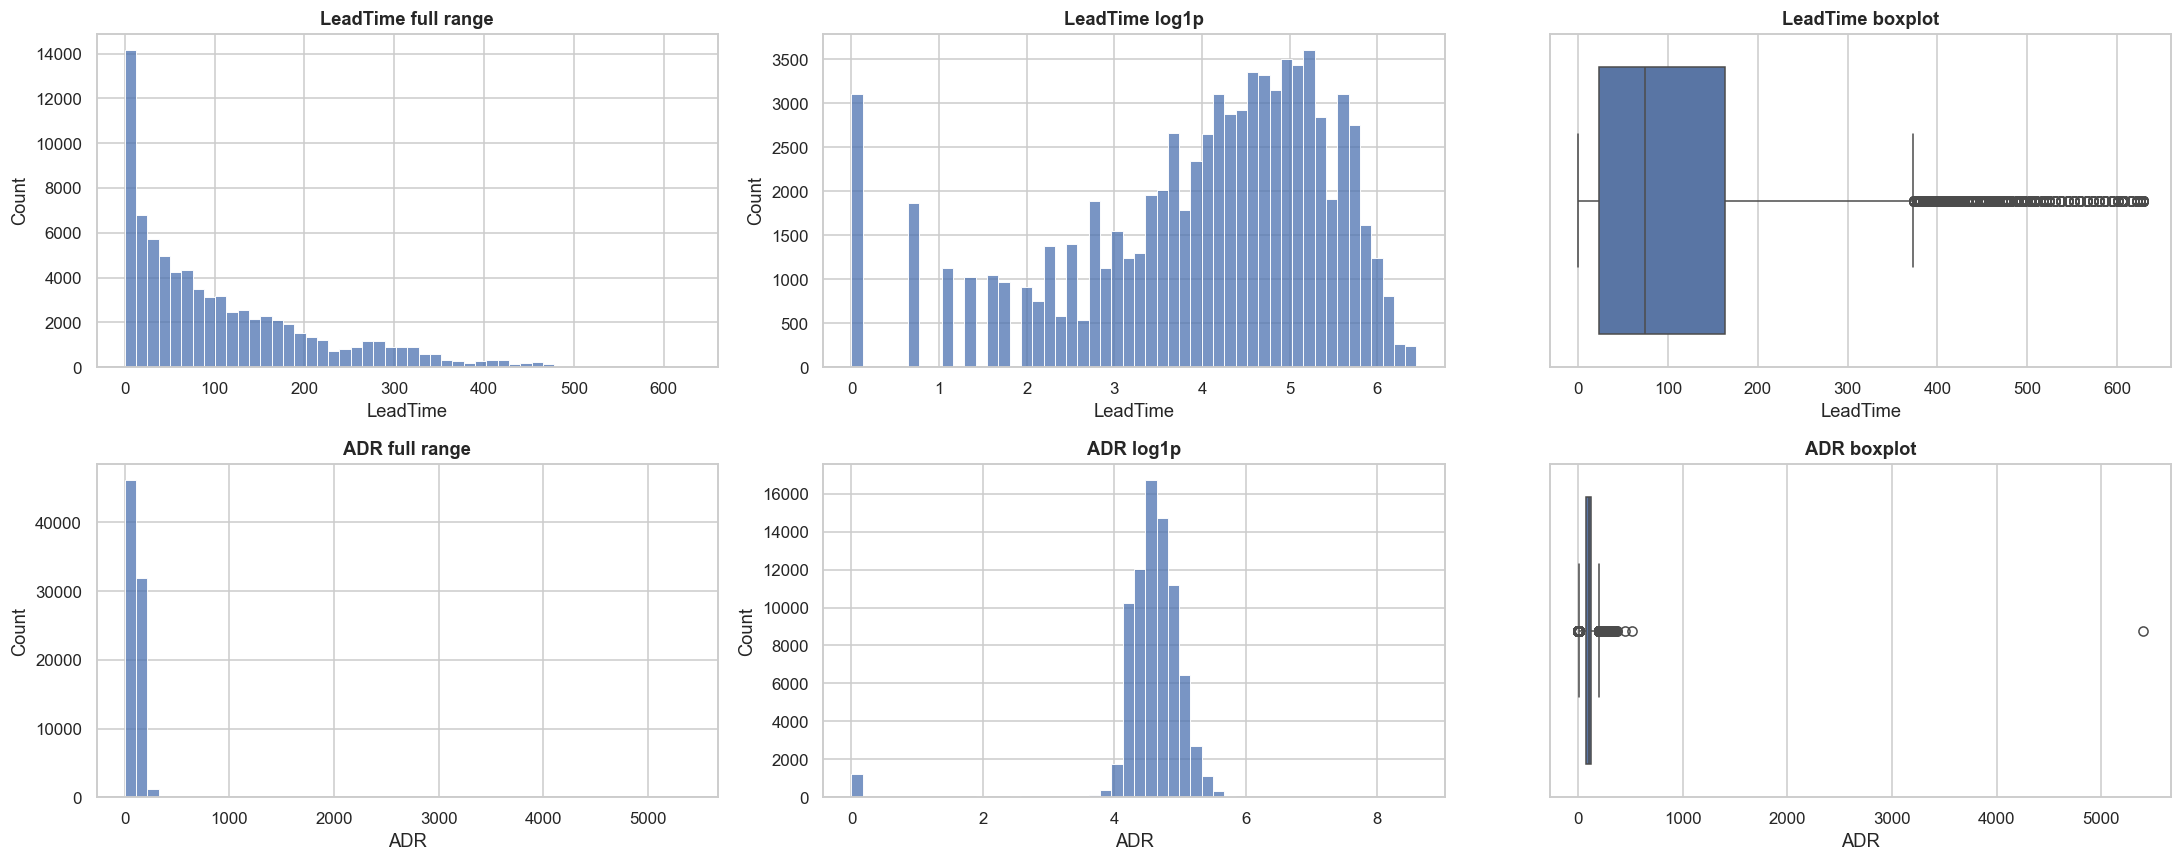

In [282]:
# We have just 2 continuous variables: ADR and LeadTime

fig, axes = plt.subplots(2, 3, figsize=(20, 8))
for row, c in enumerate(["LeadTime", "ADR"]):
    s = num[c]
    sns.histplot(s, bins=50, ax=axes[row, 0]); 
    axes[row, 0].set_title(f"{c} full range")

    sns.histplot(np.log1p(s), bins=50, ax=axes[row, 1]);
    axes[row, 1].set_title(f"{c} log1p")
    
    sns.boxplot(x=s, ax=axes[row, 2]);
    axes[row, 2].set_title(f"{c} boxplot")

plt.tight_layout()
 
# ADR Graphs are unreadable because of outliers

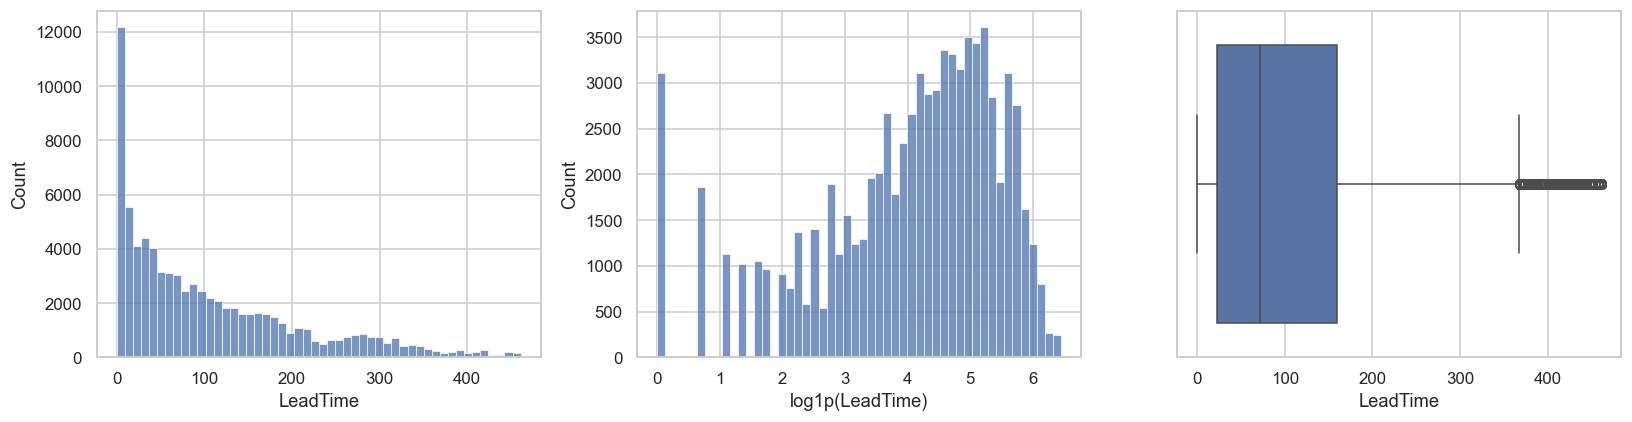

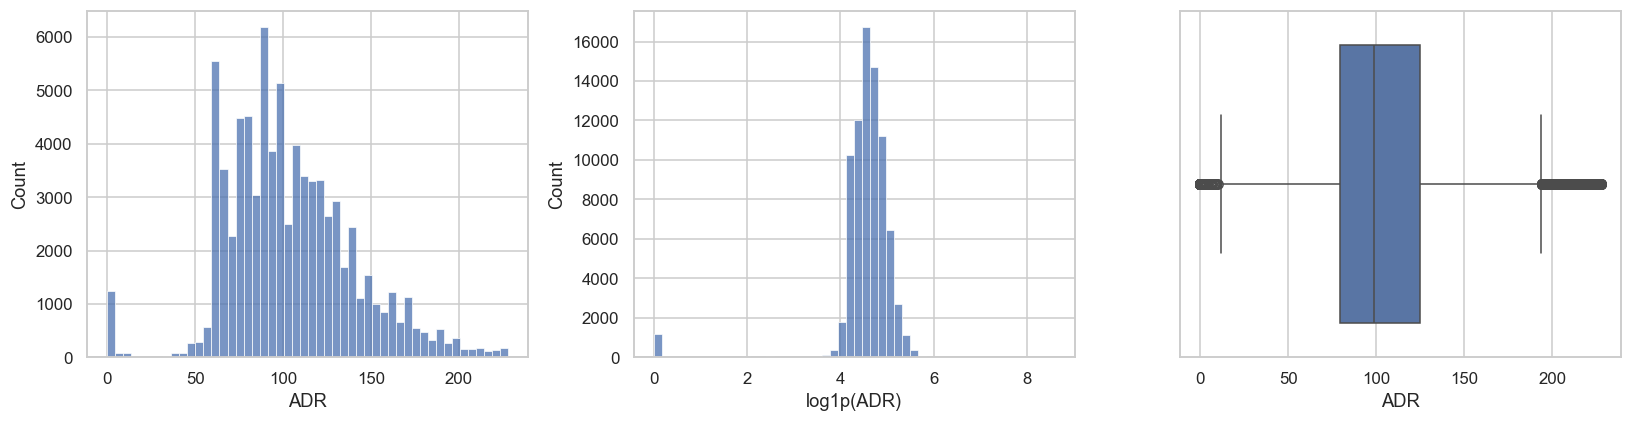

In [283]:
for c in ["LeadTime", "ADR"]:
    s = num[c]
    p99 = s.quantile(0.99)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(s[s <= p99], bins=50, ax=axes[0])
    sns.histplot(np.log1p(s), bins=50, ax=axes[1])
    sns.boxplot(x=s[s <= p99], ax=axes[2])

    axes[0].set_xlabel(c)
    axes[1].set_xlabel(f"log1p({c})")
    axes[2].set_xlabel(c)
    plt.tight_layout()

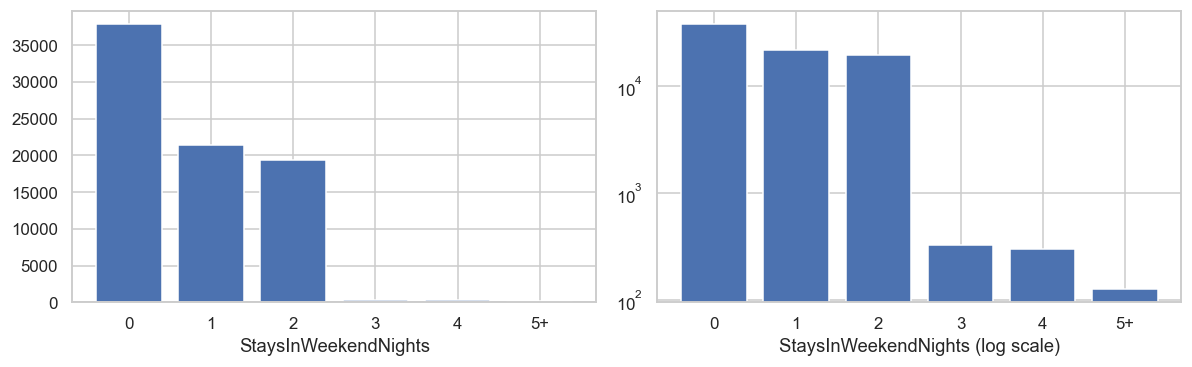

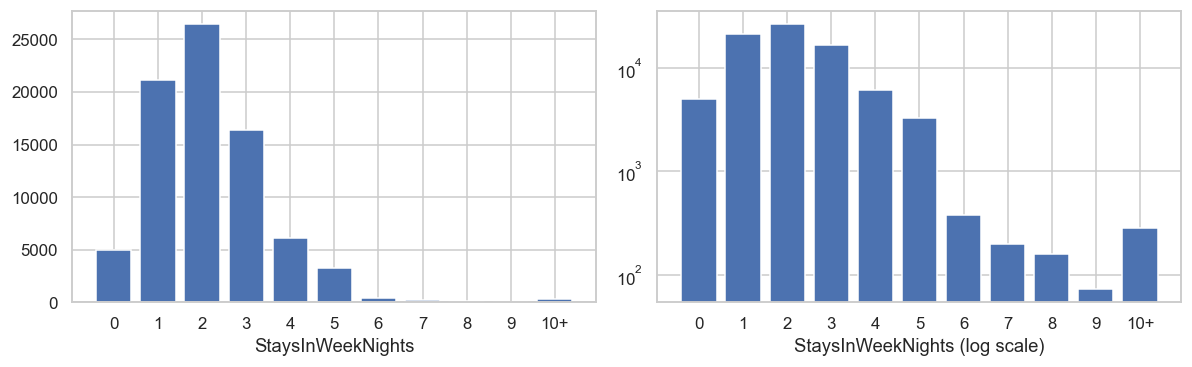

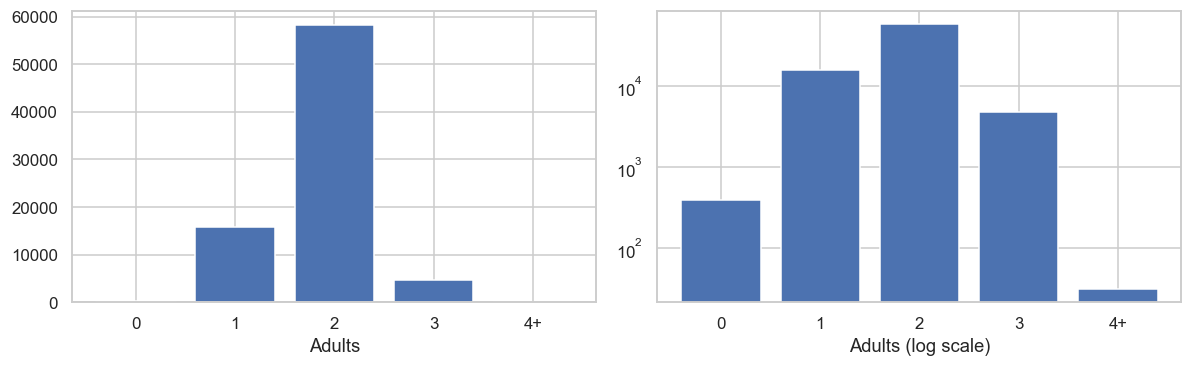

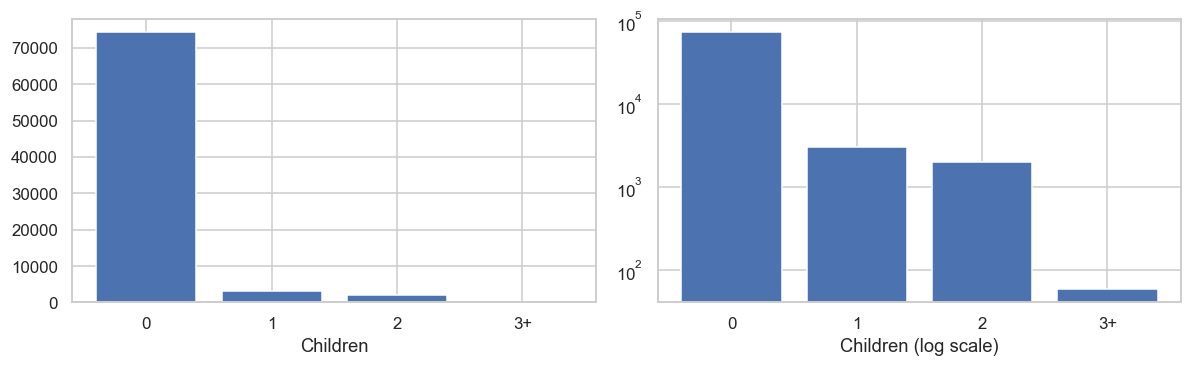

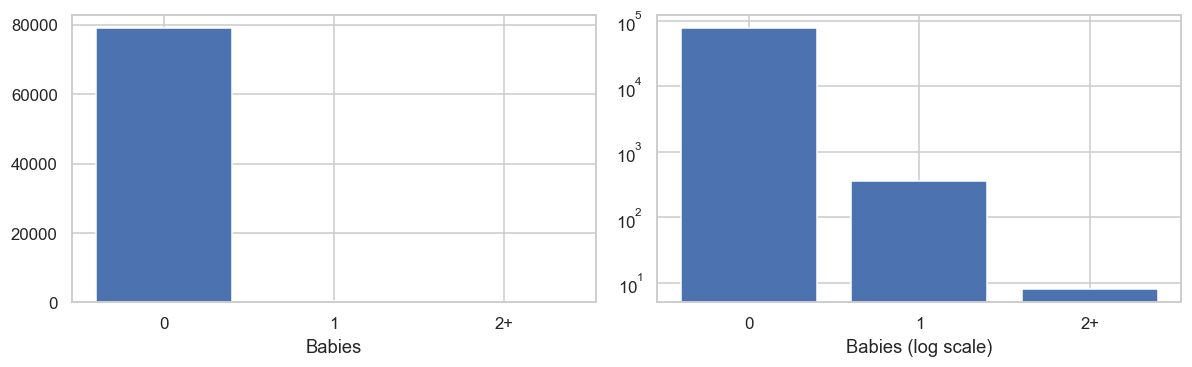

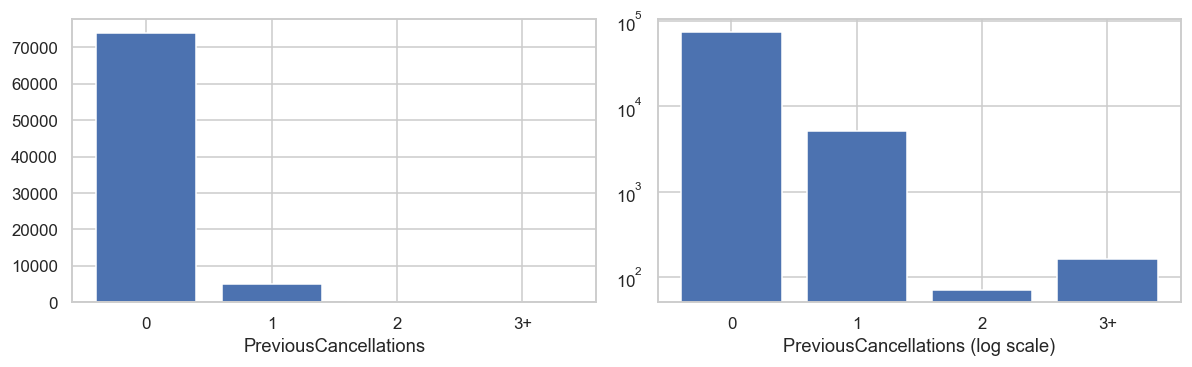

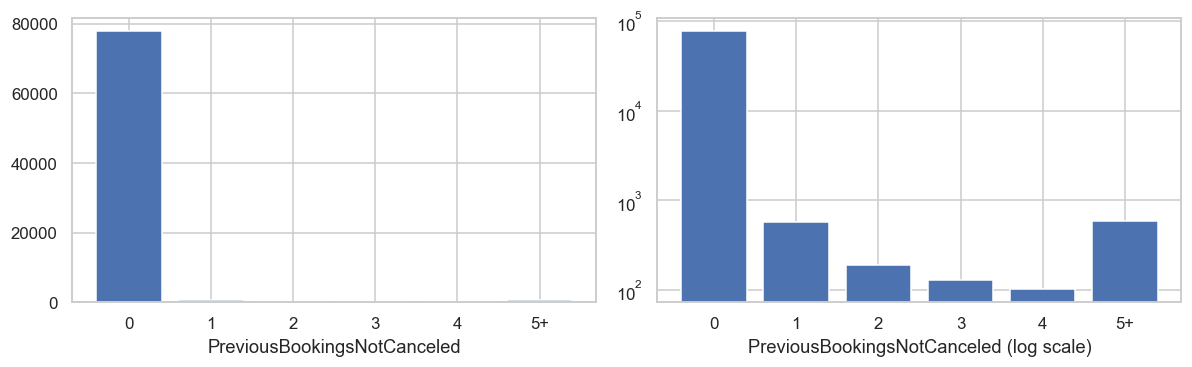

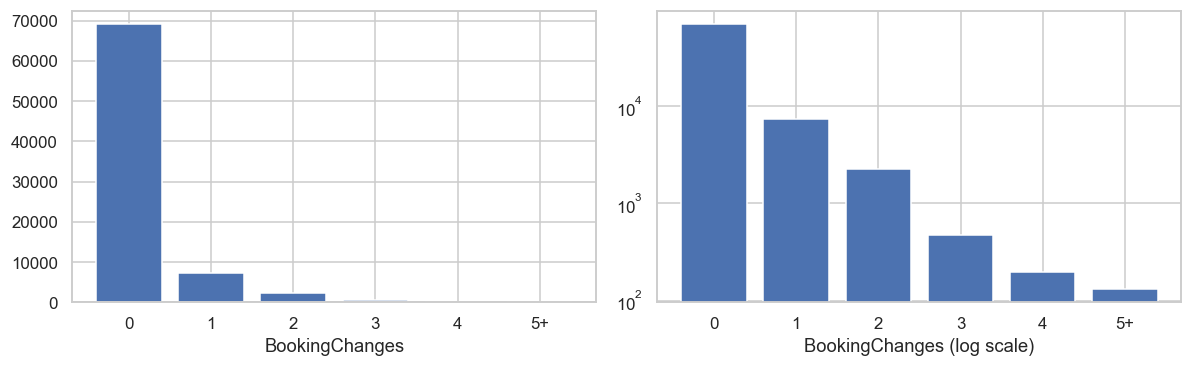

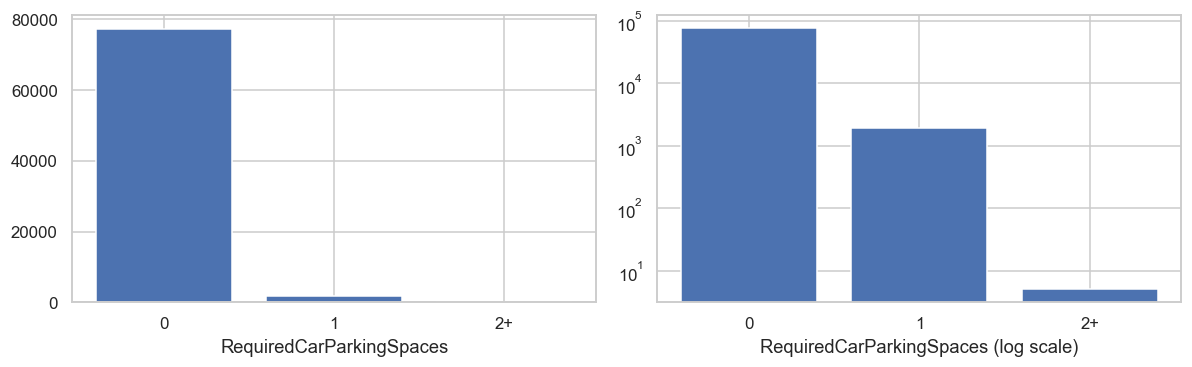

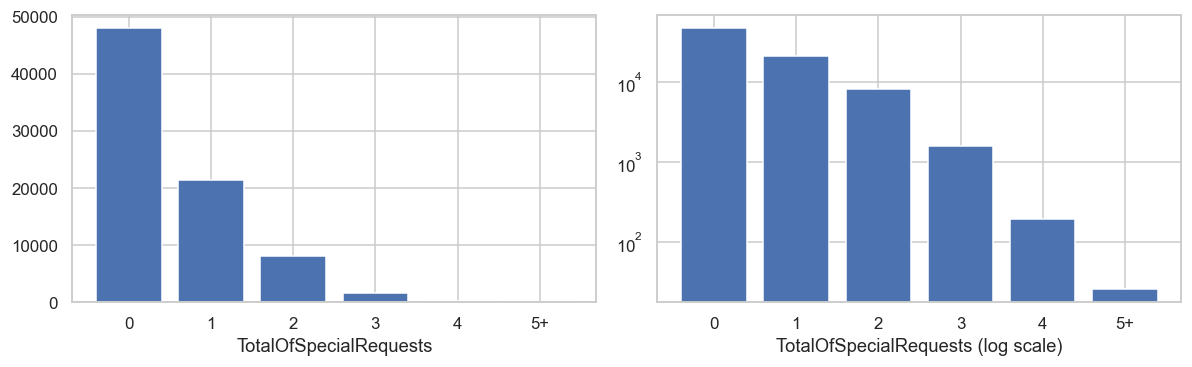

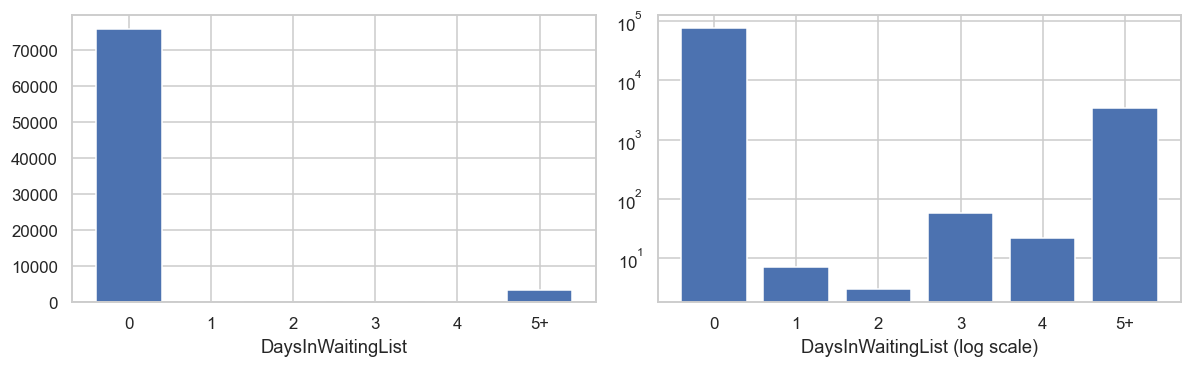

In [284]:

caps = {"StaysInWeekendNights": 5, "StaysInWeekNights": 10, "Adults": 4, "Children": 3,
        "Babies": 2, "PreviousCancellations": 3, "PreviousBookingsNotCanceled": 5,
        "BookingChanges": 5, "RequiredCarParkingSpaces": 2, "TotalOfSpecialRequests": 5, "DaysInWaitingList": 5}

for c, cap in caps.items():
    s = num[c].dropna().clip(upper=cap)
    counts = s.value_counts().reindex(range(cap + 1), fill_value=0)
    labels = [str(i) for i in range(cap)] + [f"{cap}+"]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].bar(labels, counts.values)
    axes[1].bar(labels, counts.values)
    axes[1].set_yscale("log")

    axes[0].set_xlabel(c)
    axes[1].set_xlabel(f"{c} (log scale)")
    plt.tight_layout()

# The log scale plots for better visualization (to see the small values) (Not the log1p transformation)

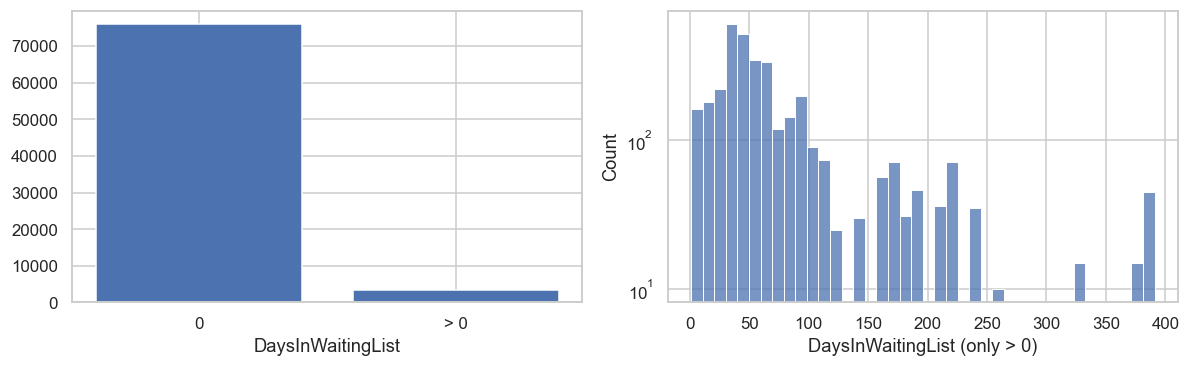

In [285]:
s = num["DaysInWaitingList"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(["0", "> 0"], [(s == 0).sum(), (s > 0).sum()])
sns.histplot(s[s > 0], bins=40, ax=axes[1])
axes[1].set_yscale("log")

axes[0].set_xlabel("DaysInWaitingList")
axes[1].set_xlabel("DaysInWaitingList (only > 0)")
plt.tight_layout()

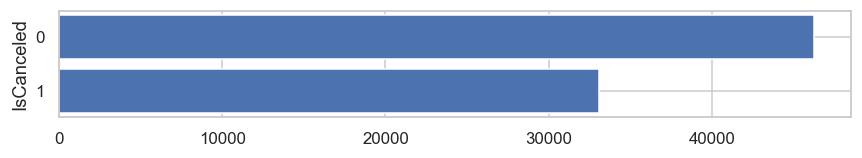

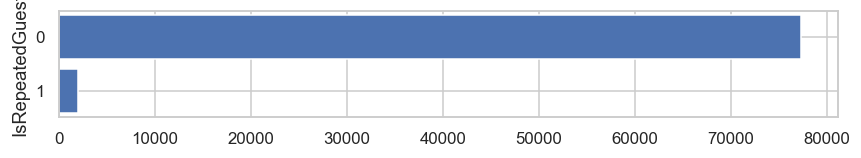

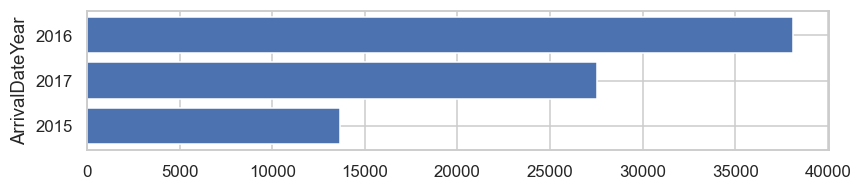

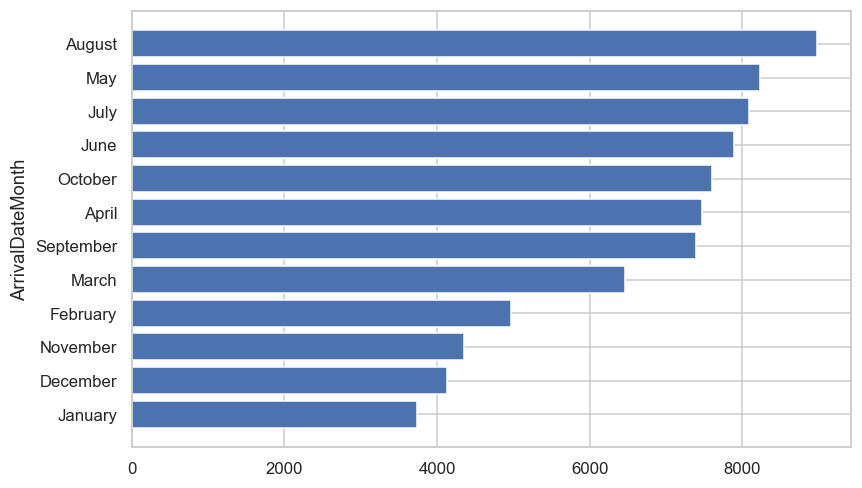

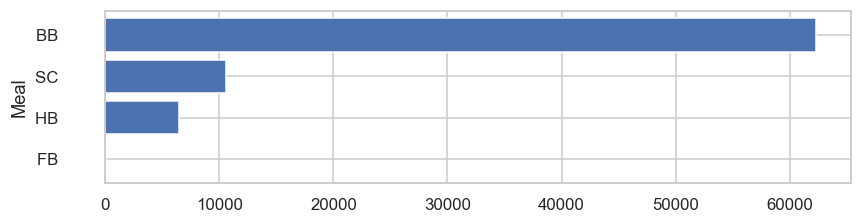

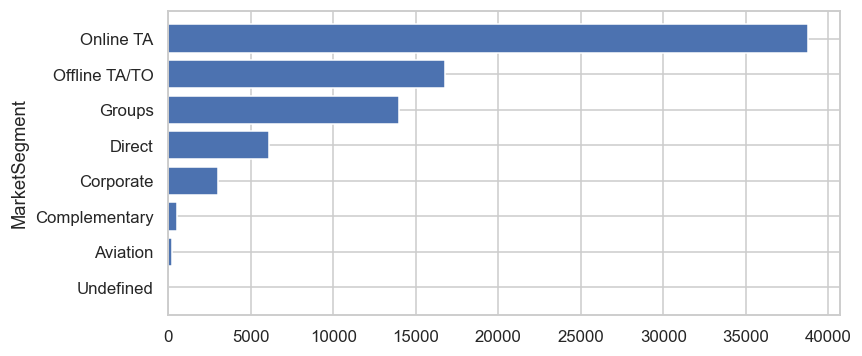

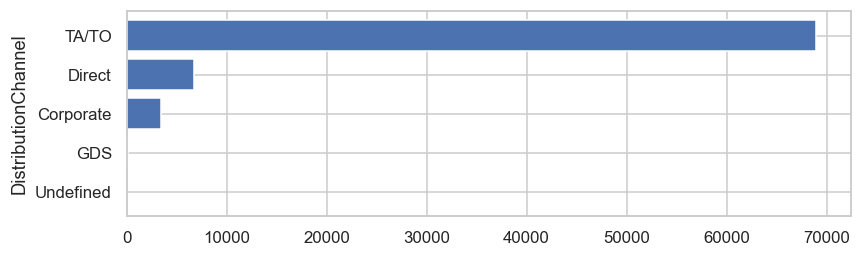

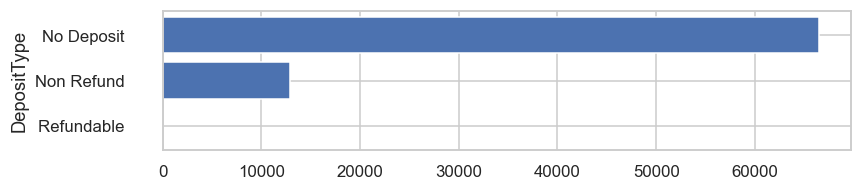

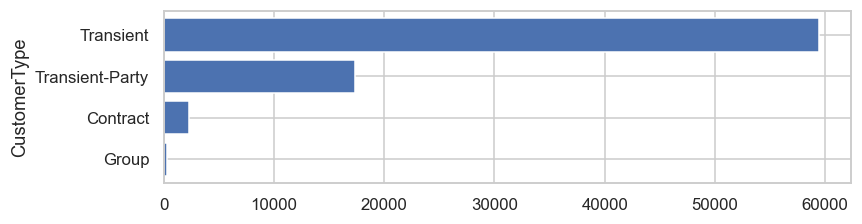

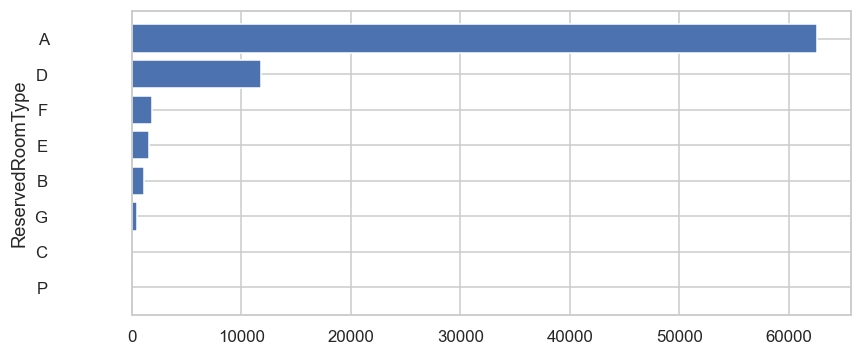

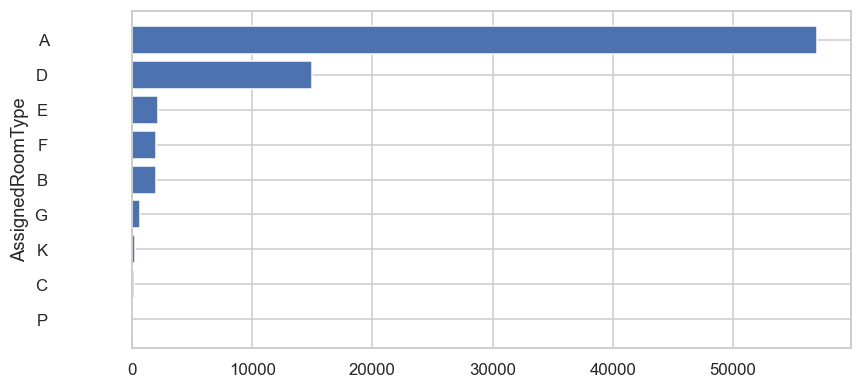

In [286]:
low_card = ["IsCanceled", "IsRepeatedGuest", "ArrivalDateYear", "ArrivalDateMonth", "Meal",
            "MarketSegment", "DistributionChannel", "DepositType", "CustomerType",
            "ReservedRoomType", "AssignedRoomType"]

for c in low_card:
    counts = df[c].value_counts()

    plt.figure(figsize=(8, 0.3 * len(counts) + 1))
    plt.barh(counts.index.astype(str), counts.values)
    plt.gca().invert_yaxis()    
    plt.ylabel(c)
    plt.tight_layout()

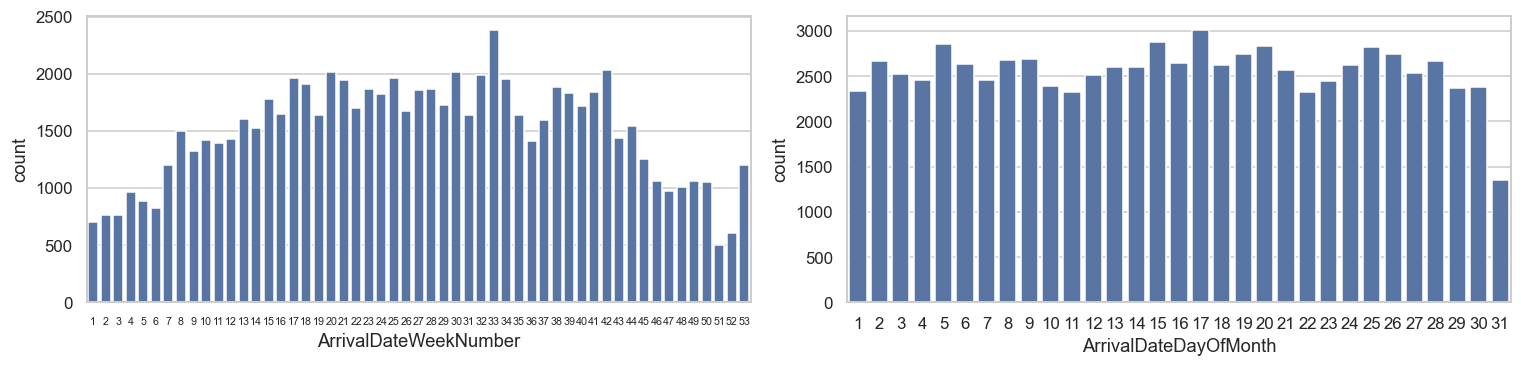

In [287]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
sns.countplot(x=df["ArrivalDateWeekNumber"], ax=axes[0])
sns.countplot(x=df["ArrivalDateDayOfMonth"], ax=axes[1])
axes[0].tick_params(axis="x", labelsize=7)
plt.tight_layout()

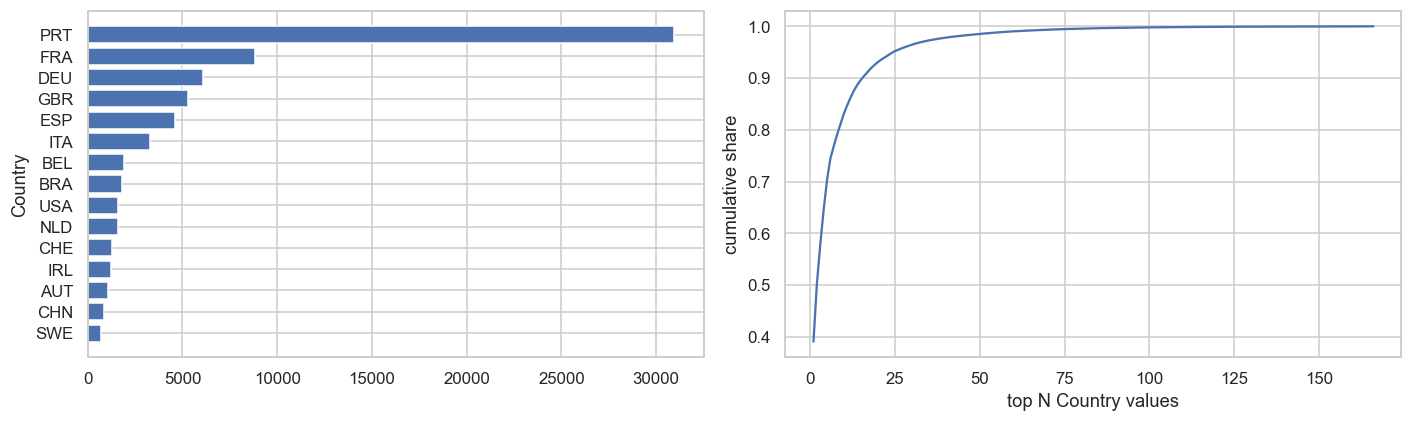

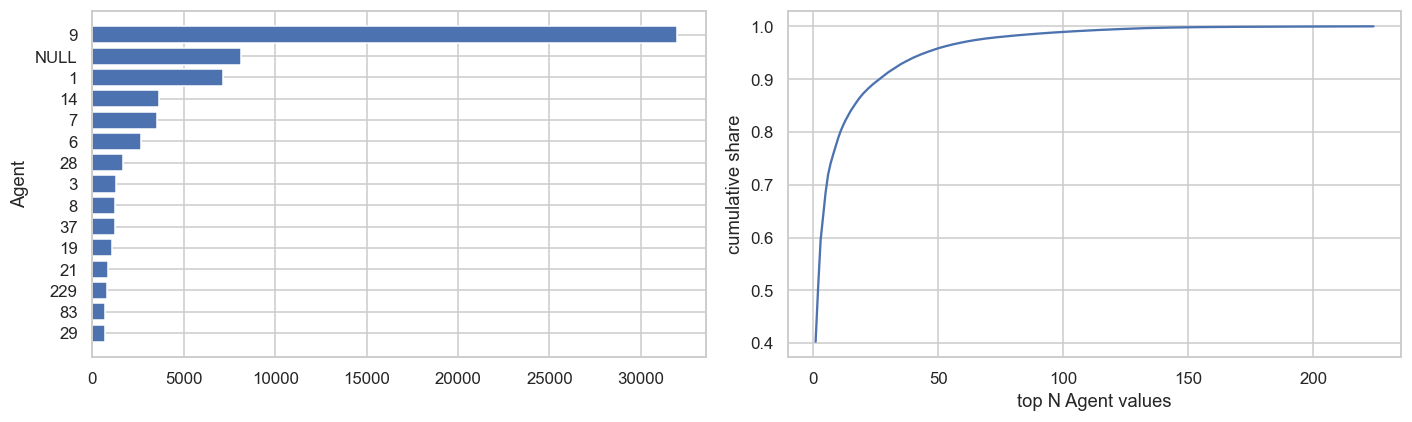

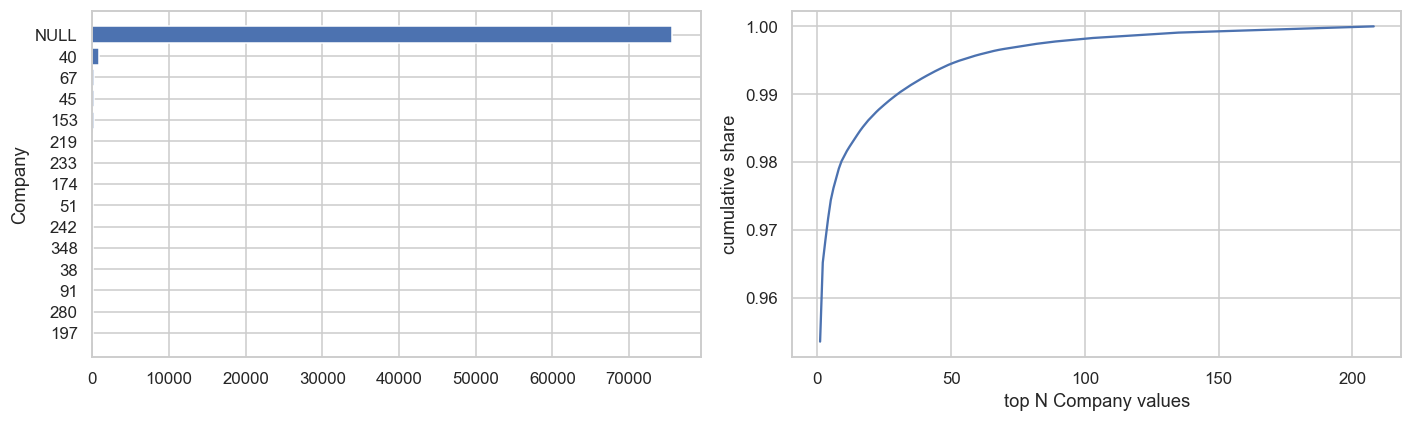

In [ ]:

for c in ["Country", "Agent", "Company"]:
    counts = df[c].astype(str).str.strip().value_counts()       # strip() Because Agent and Company are padded with spaces.
    cum = counts.cumsum() / counts.sum()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].barh(counts.head(15).index, counts.head(15).values)
    axes[0].invert_yaxis()
    axes[1].plot(range(1, len(cum) + 1), cum.values)

    axes[0].set_ylabel(c)
    axes[1].set_xlabel(f"top N {c} values")
    axes[1].set_ylabel("cumulative share")
    plt.tight_layout()
    plt.show()

In [ ]:
# Agent NULL means the customer booked without an agent. This is not an error.
#        Keep it and rename it to "NoAgent".
# # Company NULL is about 95% of the rows.
#        We may make a new column "HasCompany" (1 or 0). 
#        or keep only the top companies and use "NoCompany" and "Other".

# We will keep the top values values and rename all the rare values to "Other" before encoding.

# to avoid data leakage
# Choose the top values list using the TRAIN data only.
# A value that appears only in the test data becomes "Other".

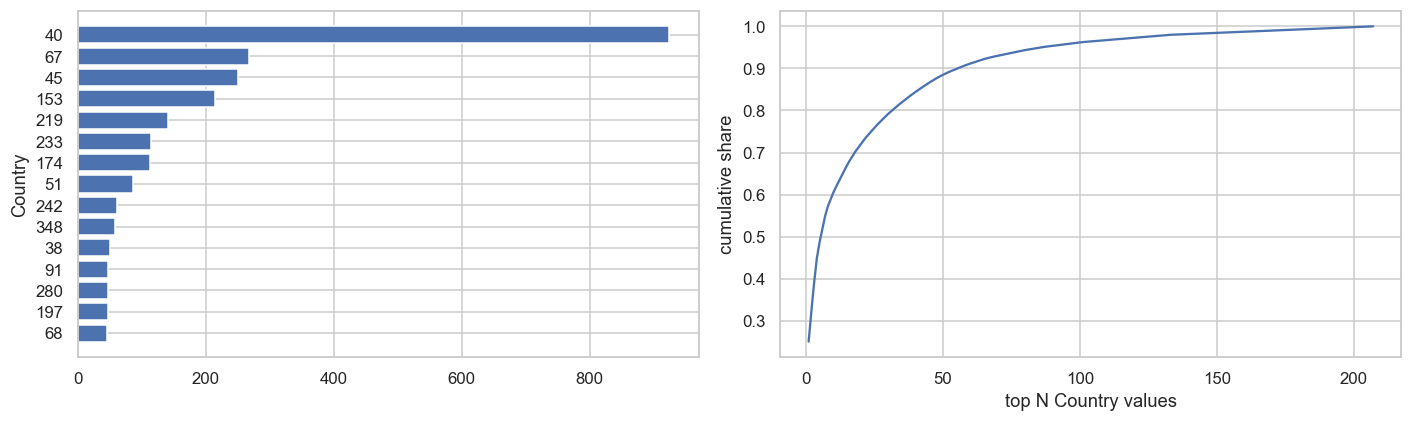

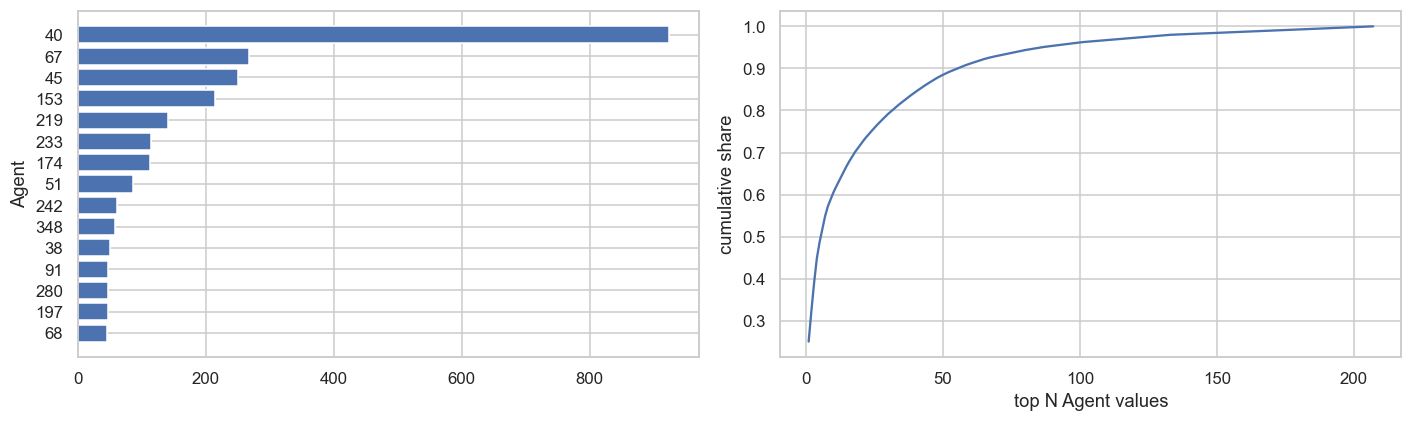

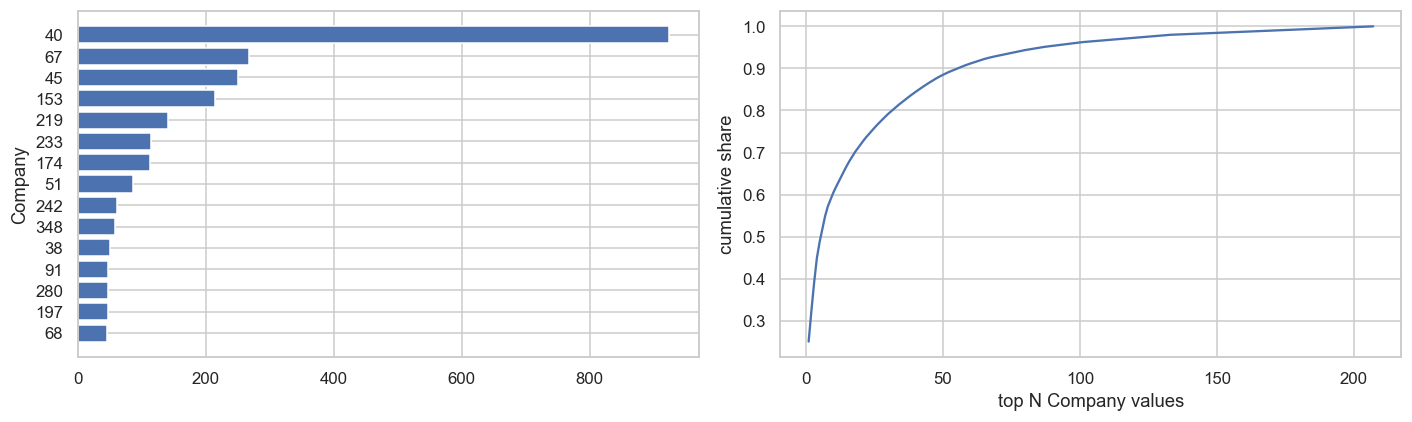

In [ ]:
# Without the Nulls
for c in ["Country", "Agent", "Company"]:
    counts = df[c].astype(str).str.strip().value_counts()
    counts = counts.drop(["NULL"], errors="ignore")   # Leave out missing values
    cum = counts.cumsum() / counts.sum()    # Comulative percentage

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].barh(counts.head(15).index, counts.head(15).values)
    axes[0].invert_yaxis()
    axes[1].plot(range(1, len(cum) + 1), cum.values)

    axes[0].set_ylabel(c)
    axes[1].set_xlabel(f"top N {c} values")
    axes[1].set_ylabel("cumulative share")
    plt.tight_layout()
    plt.show()

In [290]:
# ReservationStatus is just IsCanceled restated (crosstab showed this),
# so it would leak the answer to the classifier.
# ReservationStatusDate is only known after the outcome, so it also leaks.